# Computational Linear Algebra: PCA Homework

## Exercise 0.0: Initialization
Fill the missing values in this text box. **Remove the information of the second student if you are not working in a team**.

**Academic Year:** 2025/2026

### Team Members (Alphabetical Order):
1. Fabi, Pietro.

Now, fill the python list below with the Student IDs of the team

In [1]:
StudentIDs = [123456]  # placeholder: the real student ID (also used as the random seed) was removed for publication

## Exercise 0.1: Starting Code-Cell 

Download the .csv files from the web page of the course (*responses_hw.csv* and *columns_hw.csv*) and past them in **the same folder of this notebook**.


Then, run the cell below, **without modifing any line of code**.

The output of this code cell is **your personal subset of the original dataset**, with 2/3 of the original features (i.e., columns) and 3/4 of the original persons (i.e., rows).

### ATTENTION: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL, ANY CHANGE CAN INVALIDATE THE HOMEWORK!

In [2]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Finances
Shopping centres
Branded clothing
Entertainment spending
Spending on looks
Spending on healthy eating
Smoking
Psychology
Politics
Mathematics
Internet
PC
Chemistry
Reading
Foreign languages
Medicine
Law
Art exhibitions
Religion
Countryside, outdoors
Writing
Celebrities
Science and technology
Theatre
Fun with friends
Adrenaline sports
Pets
Movies
Thriller
Comedy
Sci-fi
Fantasy/Fairy tales
Animated
Documentary
Action
Slow songs or fast songs
Dance
Folk
Classical music
Musical
Pop
Rock
Punk
Rock n roll
Techno, Trance
Opera
Daily events
Prioritising workload
Writing notes
Final judgement
Reliability
Keeping promises
Loss of interest
Funniness
Fake
Criminal damage
Decision making
Elections
Self-criticism
Judgment calls
Hypochondria
Empathy
Eating to survive
Giving
Loneliness
Health
Changing the past
God
Dreams
Charity
Waiting
New environment
Appearence and gestures
Responding to a serious letter
Children
Getting angry


,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on healthy eating,Smoking,Psychology,Politics,Mathematics,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
396,1,5,5,5,5,5,never smoked,1,1,1,...,17,183,75,3,male,right,primary school,no,city,block of flats
254,4,5,5,4,5,4,former smoker,4,4,4,...,20,161,59,1,female,right,secondary school,no,city,block of flats
395,3,3,2,3,2,2,tried smoking,5,4,3,...,20,165,48,1,female,right,college/bachelor degree,no,city,house/bungalow
95,3,4,2,4,4,4,never smoked,4,4,2,...,20,157,54,1,female,right,secondary school,no,city,block of flats
307,5,4,3,4,3,4,tried smoking,1,2,5,...,19,185,78,2,male,left,secondary school,no,village,house/bungalow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208,1,3,4,4,4,5,tried smoking,3,3,1,...,20,173,58,1,female,right,secondary school,no,city,house/bungalow
171,3,5,3,4,4,3,former smoker,2,3,4,...,18,173,64,3,female,right,secondary school,no,city,house/bungalow
531,4,4,1,4,4,2,never smoked,5,1,3,...,17,170,55,3,female,right,secondary school,no,village,house/bungalow
56,4,3,2,2,2,5,tried smoking,1,5,2,...,20,175,83,1,male,left,secondary school,yes,city,block of flats



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on healthy eating,Smoking,Psychology,Politics,Mathematics,...,Interests or hobbies,Parents' advice,Internet usage,Storm,Darkness,Spiders,Snakes,Ageing,Dangerous dogs,Fear of public speaking
396,1,5,5,5,5,5,never smoked,1,1,1,...,5,3,most of the day,1,1,5,5,1,1,3
254,4,5,5,4,5,4,former smoker,4,4,4,...,5,5,few hours a day,1,3,3,5,3,4,2
395,3,3,2,3,2,2,tried smoking,5,4,3,...,4,3,few hours a day,2,3,2,3,1,3,2
95,3,4,2,4,4,4,never smoked,4,4,2,...,5,4,few hours a day,2,2,4,3,4,4,3
307,5,4,3,4,3,4,tried smoking,1,2,5,...,3,4,few hours a day,2,1,3,4,3,4,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208,1,3,4,4,4,5,tried smoking,3,3,1,...,5,4,few hours a day,1,1,1,1,4,4,2
171,3,5,3,4,4,3,former smoker,2,3,4,...,4,2,few hours a day,1,5,5,1,3,3,5
531,4,4,1,4,4,2,never smoked,5,1,3,...,4,4,most of the day,4,5,2,1,3,3,3
56,4,3,2,2,2,5,tried smoking,1,5,2,...,4,3,few hours a day,1,1,3,4,5,5,1



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
396,17,183,75,3,male,right,primary school,no,city,block of flats
254,20,161,59,1,female,right,secondary school,no,city,block of flats
395,20,165,48,1,female,right,college/bachelor degree,no,city,house/bungalow
95,20,157,54,1,female,right,secondary school,no,city,block of flats
307,19,185,78,2,male,left,secondary school,no,village,house/bungalow
...,...,...,...,...,...,...,...,...,...,...
208,20,173,58,1,female,right,secondary school,no,city,house/bungalow
171,18,173,64,3,female,right,secondary school,no,city,house/bungalow
531,17,170,55,3,female,right,secondary school,no,village,house/bungalow
56,20,175,83,1,male,left,secondary school,yes,city,block of flats


## Exercise 0.2: Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.

For reproducibility, **no extra modules are allowed**.

**DO NOT IMPORT NUMPY NOR PANDAS**, they are already imported.

In [3]:
# DO NOT IMPORT NUMPY AND PANDAS - Already imported
%matplotlib widget
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, silhouette_samples
from matplotlib.lines import Line2D
import matplotlib.cm as cm

## Exercise 1. Dataset Preprocessing

In this exercise, you have to do the following operations on the dataset of the features **responses_ft**:
1. Create a new dataframe called **responses_ft_enc** by encoding the categorical features (if they exist), motivating your choices;
1. Create a new dataframe called **responses_ft_pp** by preprocessing the data in **responses_ft_enc**, according to the scaler reported in the cell below.

In [4]:
print(f'*** YOU HAVE TO APPLY A PREPROCESSING USING THE {your_scaler}')

*** YOU HAVE TO APPLY A PREPROCESSING USING THE StandardScaler


For doing this exercise, fill the cells below following the instructions you read.

#### Describe and motivate the encoding operations you will apply (max 150 words):
The majority of the features are numerical, except for 'Smoking' and 'Internet usage', which are categorical.
Since these variables possess an intrinsic natural order for example, 'few hours a day' represents a lower usage intensity than 'most of the day', we will apply Ordinal Encoding. This transformation maps the categories to incremental integers 0, 1, 2..., preserving the hierarchical relationship of the data while converting it into a numeric format required for the analysis.

#### Describe the preprocessing operation you will apply and comment the effects it may have on the data (max 150 words):
We will first apply the Ordinal Encoder to the categorical variables to ensure the entire dataset is numeric. Subsequently, we will apply the StandardScaler to normalize all features to a mean of 0 and a standard deviation of 1

#### Write the code for performing the encoding and preprocessing operations of the exercise. Show the encoded data and the preprocessed data you obtain, plus any additional table/value that can be useful for commenting the results:

In [5]:
responses_ft_enc = responses_ft.copy()

categories = [['never smoked', 'tried smoking', 'former smoker', 'current smoker'],
              ['less than an hour a day', 'few hours a day', 'most of the day']]

oe = OrdinalEncoder(categories=categories, dtype=np.int64)

cols_to_transform = ["Smoking", "Internet usage"]
responses_ft_enc[cols_to_transform] = oe.fit_transform(responses_ft[cols_to_transform])

ss = StandardScaler()
responses_ft_pp = ss.fit_transform(responses_ft_enc)
responses_ft_pp = pd.DataFrame(responses_ft_pp, columns=responses_ft.columns.values, index=responses_ft.index)

print('*** THIS IS THE ENCODED DATASET')
display(responses_ft_enc)

print('*** THIS IS PREPROCESSED DATASET')
display(responses_ft_pp)

*** THIS IS THE ENCODED DATASET


,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on healthy eating,Smoking,Psychology,Politics,Mathematics,...,Interests or hobbies,Parents' advice,Internet usage,Storm,Darkness,Spiders,Snakes,Ageing,Dangerous dogs,Fear of public speaking
396,1,5,5,5,5,5,0,1,1,1,...,5,3,2,1,1,5,5,1,1,3
254,4,5,5,4,5,4,2,4,4,4,...,5,5,1,1,3,3,5,3,4,2
395,3,3,2,3,2,2,1,5,4,3,...,4,3,1,2,3,2,3,1,3,2
95,3,4,2,4,4,4,0,4,4,2,...,5,4,1,2,2,4,3,4,4,3
307,5,4,3,4,3,4,1,1,2,5,...,3,4,1,2,1,3,4,3,4,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208,1,3,4,4,4,5,1,3,3,1,...,5,4,1,1,1,1,1,4,4,2
171,3,5,3,4,4,3,2,2,3,4,...,4,2,1,1,5,5,1,3,3,5
531,4,4,1,4,4,2,0,5,1,3,...,4,4,2,4,5,2,1,3,3,3
56,4,3,2,2,2,5,1,1,5,2,...,4,3,1,1,1,3,4,5,5,1


*** THIS IS PREPROCESSED DATASET


,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on healthy eating,Smoking,Psychology,Politics,Mathematics,...,Interests or hobbies,Parents' advice,Internet usage,Storm,Darkness,Spiders,Snakes,Ageing,Dangerous dogs,Fear of public speaking
396,-1.735047,1.320710,1.523897,1.517613,1.562205,1.414114,-1.352603,-1.714558,-1.275654,-1.036165,...,1.243718,-0.289994,2.040428,-0.829971,-1.048914,1.410192,1.333275,-1.116022,-1.518020,0.132728
254,0.906679,1.320710,1.523897,0.678365,1.562205,0.489642,0.648617,0.693119,1.040665,1.214048,...,1.243718,2.135414,0.012026,-0.829971,0.586681,0.093666,1.333275,0.370049,0.725753,-0.696410
395,0.026104,-0.205042,-0.748476,-0.160884,-0.905461,-1.359304,-0.351993,1.495678,1.040665,0.463977,...,0.407966,-0.289994,0.012026,0.043138,0.586681,-0.564597,-0.009286,-1.116022,-0.022172,-0.696410
95,0.026104,0.557834,-0.748476,0.678365,0.739650,0.489642,-1.352603,0.693119,1.040665,-0.286094,...,1.243718,0.922710,0.012026,0.043138,-0.231117,0.751929,-0.009286,1.113085,0.725753,0.132728
307,1.787255,0.557834,0.008982,0.678365,-0.082906,0.489642,-0.351993,-1.714558,-0.503548,1.964119,...,-0.427786,0.922710,0.012026,0.043138,-1.048914,0.093666,0.661994,0.370049,0.725753,0.961865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208,-1.735047,-0.205042,0.766440,0.678365,0.739650,1.414114,-0.351993,-0.109440,0.268559,-1.036165,...,1.243718,0.922710,0.012026,-0.829971,-1.048914,-1.222860,-1.351848,1.113085,0.725753,-0.696410
171,0.026104,1.320710,0.008982,0.678365,0.739650,-0.434831,0.648617,-0.911999,0.268559,1.214048,...,0.407966,-1.502699,0.012026,-0.829971,2.222276,1.410192,-1.351848,0.370049,-0.022172,1.791002
531,0.906679,0.557834,-1.505934,0.678365,0.739650,-1.359304,-1.352603,1.495678,-1.275654,0.463977,...,0.407966,0.922710,2.040428,1.789354,2.222276,-0.564597,-1.351848,0.370049,-0.022172,0.132728
56,0.906679,-0.205042,-0.748476,-1.000132,-0.905461,1.414114,-0.351993,-1.714558,1.812771,-0.286094,...,0.407966,-0.289994,0.012026,-0.829971,-1.048914,0.093666,0.661994,1.856120,1.473677,-1.525547


#### Comment the results obtained after the preprocessing operation (max 100 words):
Our preprocessing successfully transformed the dataset into a homogeneous numerical matrix suitable for our purpose. The Ordinal Encoding mapped the categorical variables to integers and then the StandardScaler normalized all the features. This transformation is crucial as it removes scale bias, ensuring that features with originally larger ranges do not disproportionately dominate the variance calculations in PCA or the Euclidean distance metrics in clustering.

## Exercise 2. Analyzing the Variance and the PCs

In this exercise, you have to do the following operations:
1. compute and visualize the variance of all the features in *responses_ft_enc* and *responses_ft_pp*;
1. compute all the $n$ Principal Components (PCs) for *responses_ft_enc* and *responses_ft_pp*, separately, and visualize the curves of the cumulative explained variances.

For doing this exercise, fill the cells below following the instructions you read.

#### Write the code for computing and visualizing the variance of the features of the two datasets:

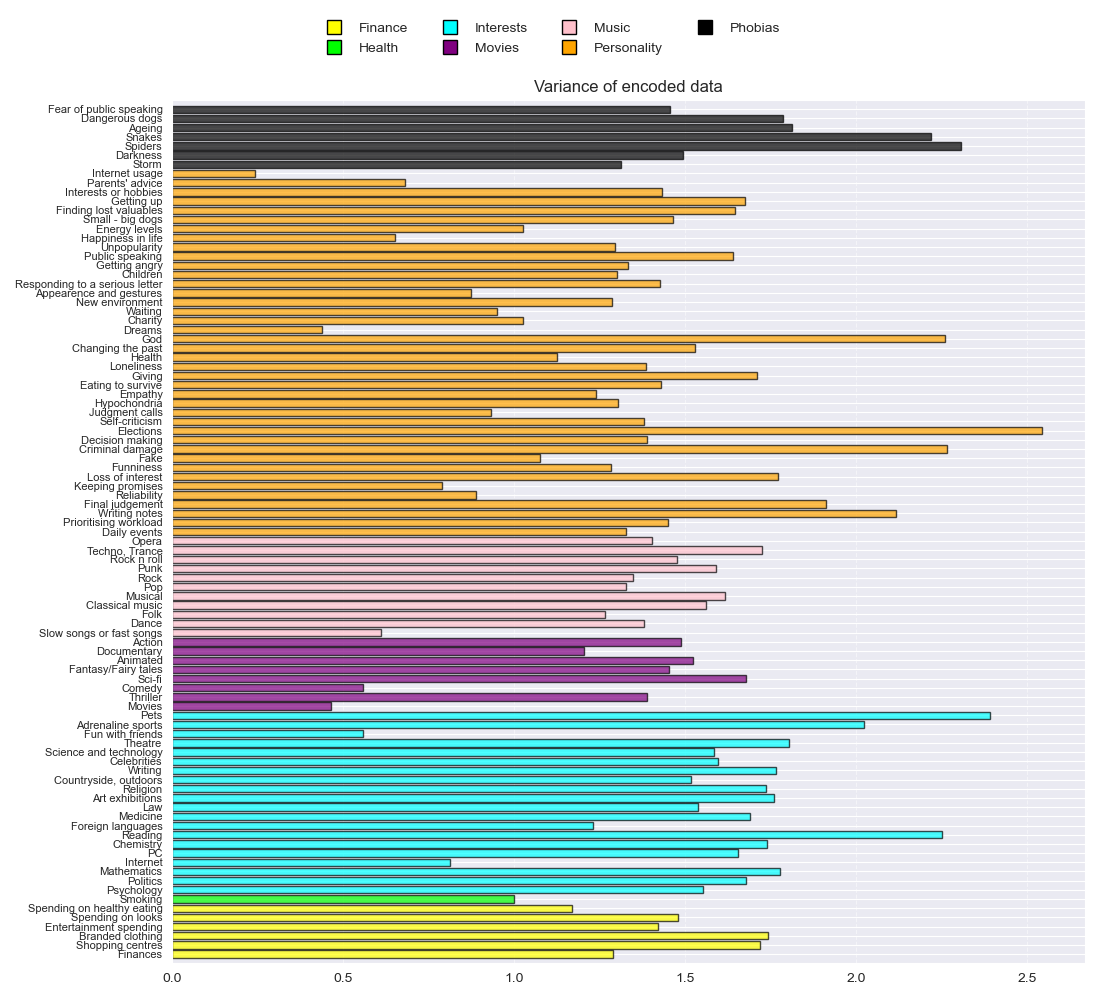

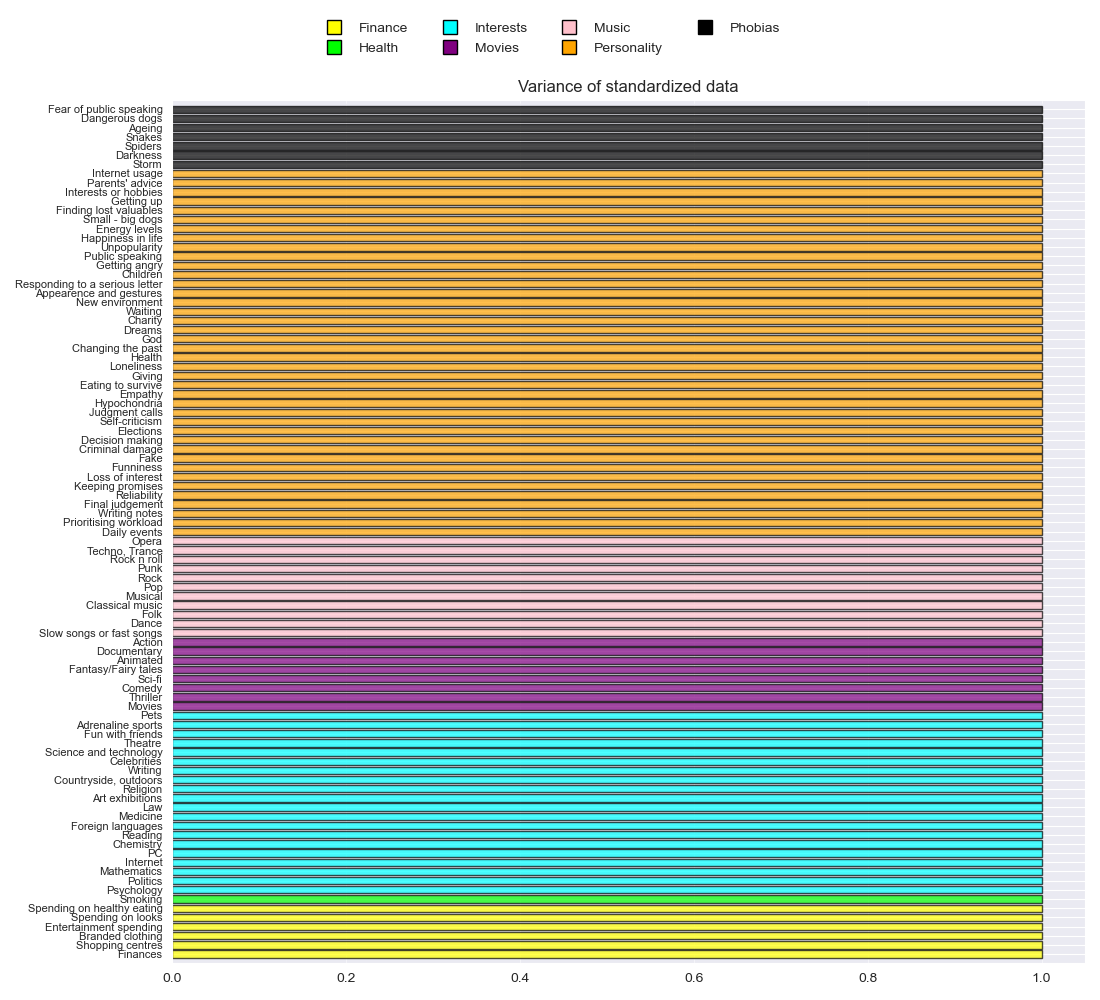

In [6]:
def create_colors_and_legend(ft_names, ft_category):
    legend_created = []
    category_colors = {
    'Finance': '#FFFF00',
    'Health': '#00FF00',
    'Interests': '#00FFFF',
    'Movies': '#800080',
    'Music': '#FFC0CB',
    'Personality': '#FFA500',
    'Phobias': '#000000'}
    
    for key in category_colors.keys():
        legend_created.append(Line2D([0], [0], marker='s', color='w', label=key, markerfacecolor=category_colors[key], mec='black', markersize=10))
    
    feature_to_category_map = {}
    for cat, it in ft_category.items():
        for i in it:
            feature_to_category_map[i] = cat
    
    bar_colors = []
    for feature in ft_names:
        cat = feature_to_category_map.get(feature)
        color = category_colors.get(cat, '#CCCCCC')
        bar_colors.append(color)
    
    return bar_colors, legend_created

def variance_graph(values, positions, names, word, colors_map, legend):
    fig_var = plt.figure(figsize=(11, 10))
    plt.barh(positions, values, color=colors_map, edgecolor='black', alpha=0.7)
    plt.yticks(positions, names, fontsize=8)
    plt.ylim(-1, len(names))
    plt.title(f"Variance of {word} data")
    plt.grid(True, axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.subplots_adjust(top=0.9) 
    fig_var.legend(handles=legend, loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=4, frameon=False, title_fontsize='large')
    plt.show()

enc_variance = np.var(responses_ft_enc, axis=0)
pp_variance = np.var(responses_ft_pp, axis=0)

feature_names = responses_ft.columns.values
y_pos = np.arange(len(feature_names))

categories_colors, categories_legend = create_colors_and_legend(feature_names, features_by_type)

plt.close("all")
variance_graph(enc_variance, y_pos, feature_names, "encoded", categories_colors, categories_legend)
variance_graph(pp_variance, y_pos, feature_names, "standardized", categories_colors, categories_legend)

#### Comment the results obtained for the variances (max 150 words):
If we applied PCA to the non standardized data, the algorithm would mistakenly identify these large-scale features as the most 'informative' components simply due to their magnitude.
In contrast, the standardized dataset shows a uniform variance of 1 for all features. This confirms that the scaling was successful. By equalizing the variance, we ensure that PCA will now extract components based on the true correlation structure of the data, rather than being biased by the arbitrary units of measurement


#### Write the code for computing all the $n$ PCs of the two datasets, separately, and for visualizing the curves of cumulative explained variances:

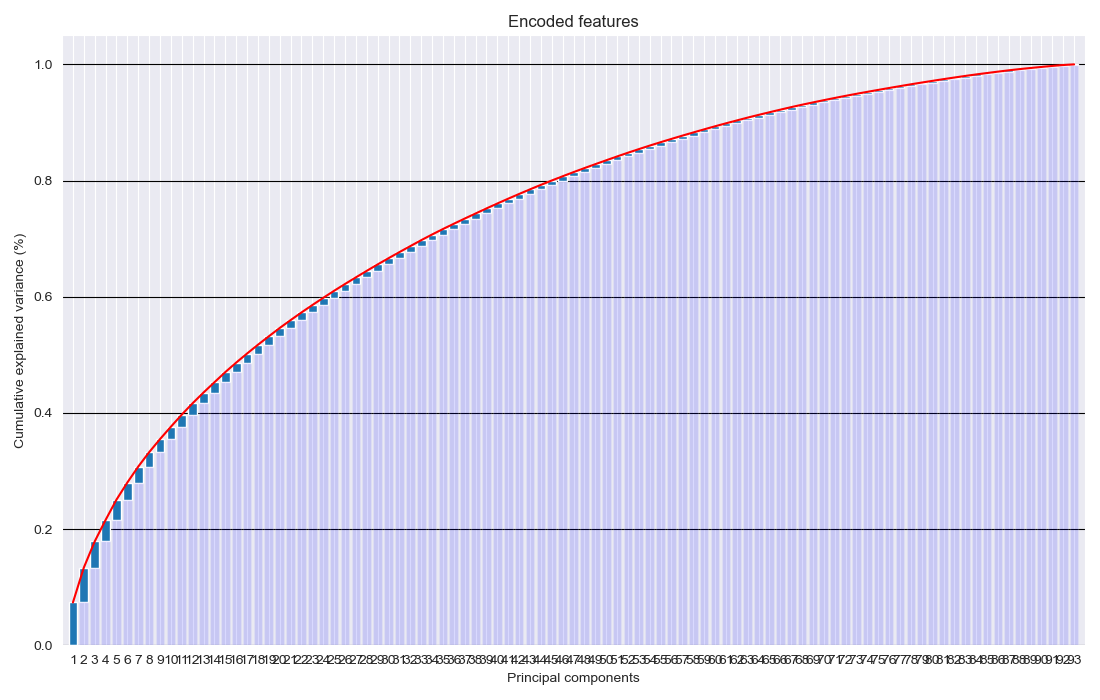

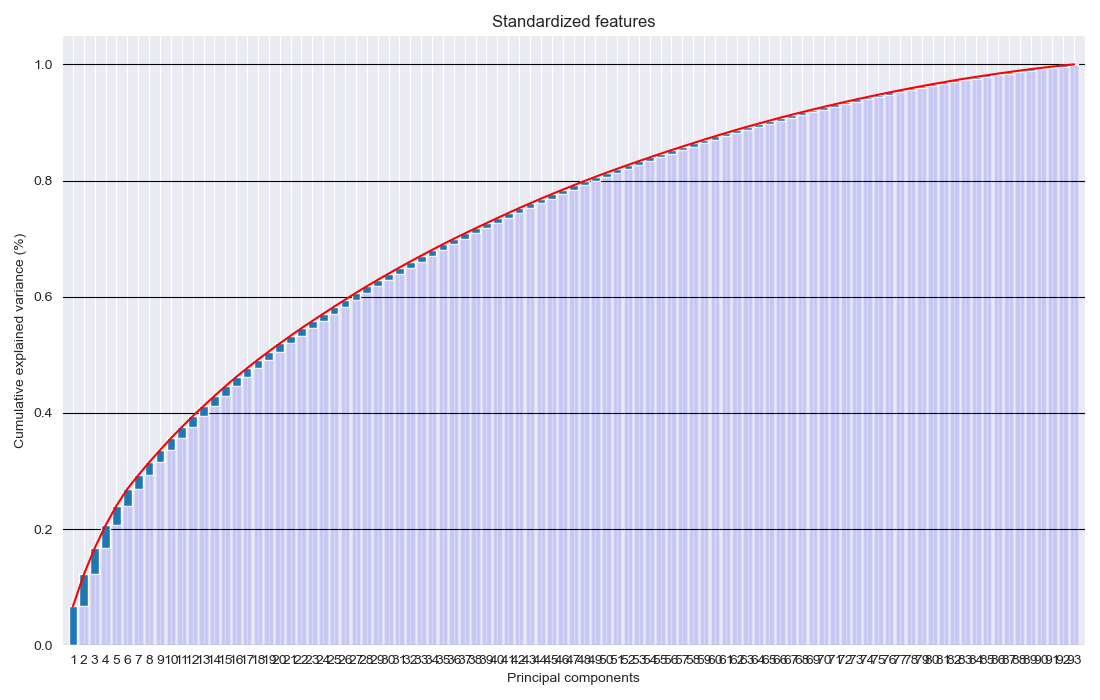

In [7]:
def cumulative_variance_graph(pca_passed, word):
    plt.figure(figsize=(11, 7))
    plt.bar(np.arange(pca_passed.n_features_in_), pca_passed.explained_variance_ratio_, bottom=np.insert(np.cumsum(pca_passed.explained_variance_ratio_), 0, 0)[:-1])
    plt.bar(np.arange(pca_passed.n_features_in_), np.insert(np.cumsum(pca_passed.explained_variance_ratio_), 0, 0)[:-1], color='b', alpha=0.15)
    plt.plot(np.cumsum(pca_passed.explained_variance_ratio_), 'r')
    plt.title(f'{word} features')
    plt.xticks(ticks=np.arange(pca_passed.n_features_in_), labels=[i for i in range(1, pca_passed.n_features_in_ + 1)])
    plt.xlim(-1, pca_passed.n_features_in_)
    plt.xlabel('Principal components')
    plt.ylabel('Cumulative explained variance (%)')
    plt.grid(color="black", axis="y")
    plt.tight_layout()
    plt.show()

plt.close("all")

pca_enc = PCA()
pca_pp = PCA()

pca_enc.fit(responses_ft_enc)
pca_pp.fit(responses_ft_pp)

cumulative_variance_graph(pca_enc, "Encoded")
cumulative_variance_graph(pca_pp, "Standardized")

#### Comment the results obtained for the cumulative explained variances, knowing the vaues in the datasets and the fetures' variances (max 150 words):
The unscaled dataset exhibits a steeper ascent, this occurs because variables with large numerical magnitudes dominate the variance calculation.
In contrast, the standardized dataset displays a much more gradual slope. It requires significantly more components to explain a high percentage of variance.

## Exercise 3. Dimensionality Reduction and PC Interpretation

In this exercise, you have to do the following operations:
1. For the dataset *responses_ft_pp*, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
1. Visualize as a barplot the explained variance (as percentage) for each PC, and report the preserved explained variance (as percentage) by the $m$ PCs.
1. Visualize all the PCs as barplots and give an interpretation and a name to them, **motivating your choices**.
1. Transform the *responses_ft_pp* data into their $m$-dimensional representation via PCA. Store the transformed data in the variable *responses_ft_pca*;
1. Visualize the the score graph. If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs (given at the previous step) on the axes** for better understanding the results.

#### Write the code for computing the new PCA, for visualizing the $m$ PCs as barplots:


Total variance preserved from the first 5 PC: 24.03%


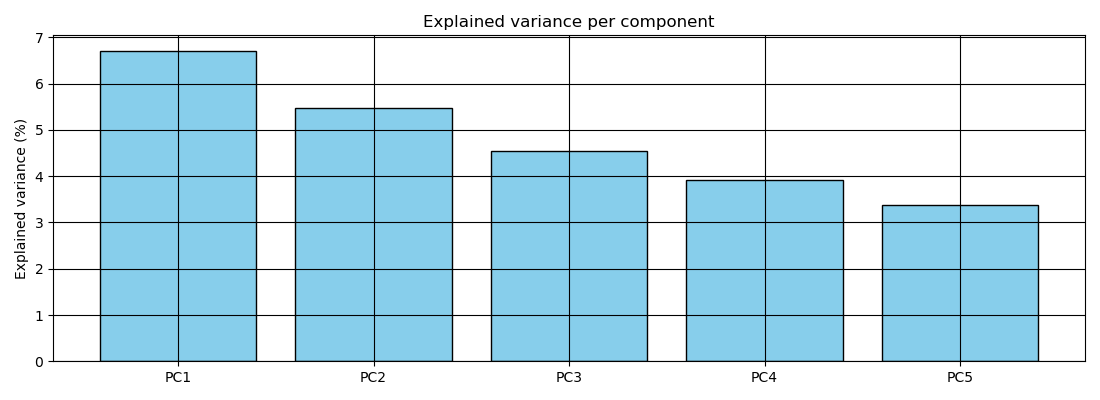

In [13]:
plt.close("all")
m_prime = np.argmax(np.cumsum(pca_pp.explained_variance_ratio_) > 0.33) + 1
m = min(5, m_prime)

pca_ft = PCA(n_components=m)
pca_ft.fit(responses_ft_pp)

exp_var_ratio = pca_ft.explained_variance_ratio_
exp_var_percentage = exp_var_ratio * 100
total_preserved_variance = np.sum(exp_var_percentage)

print('')
print(f"Total variance preserved from the first {m} PC: {total_preserved_variance:.2f}%")
plt.figure(figsize=(11,4))
bars = plt.bar([f'PC{i+1}' for i in range(m)], exp_var_percentage, color='skyblue', edgecolor='black')
plt.title(f'Explained variance per component')
plt.ylabel('Explained variance (%)')
plt.grid(True, color="black")
plt.tight_layout()
plt.show()

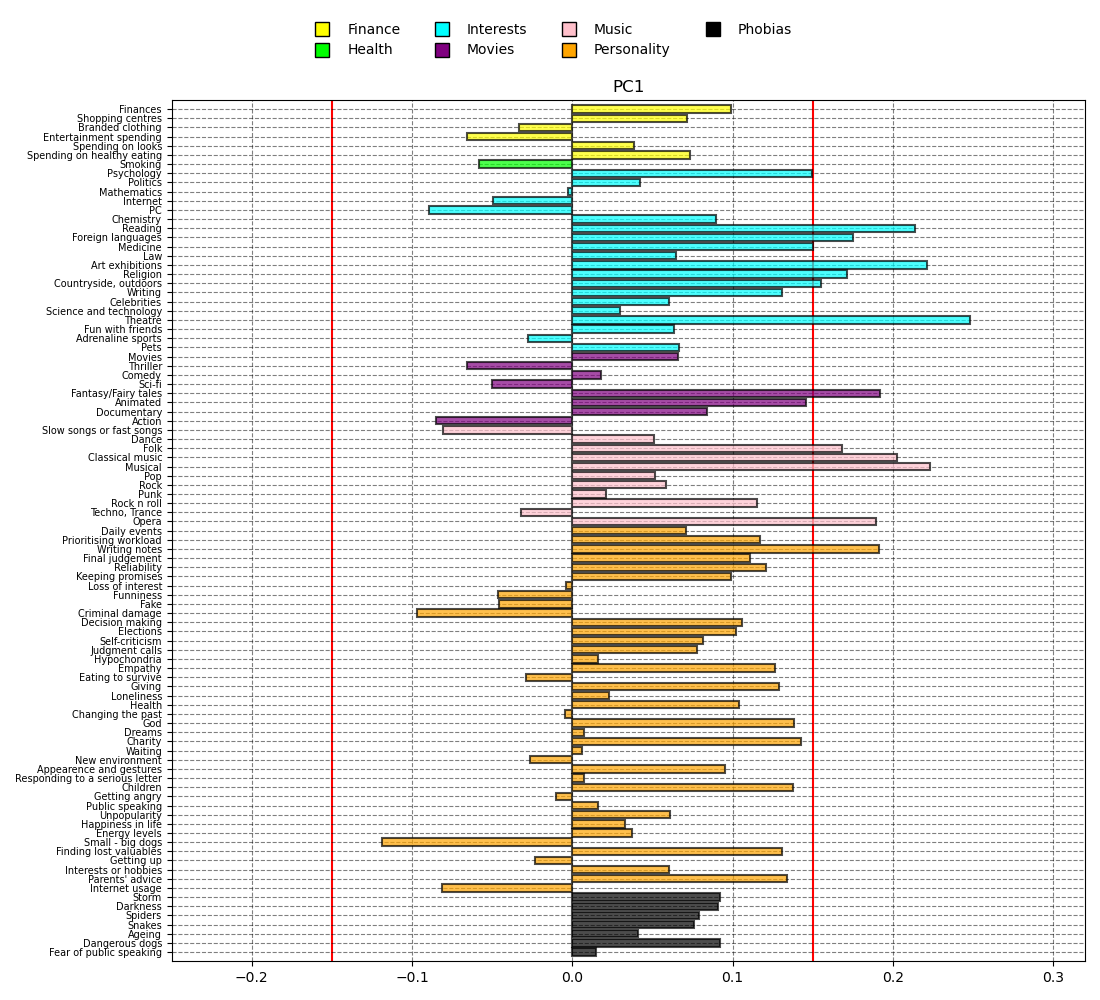

High value positive components: ['Reading' 'Foreign languages' 'Medicine' 'Art exhibitions' 'Religion'
 'Countryside, outdoors' 'Theatre' 'Fantasy/Fairy tales' 'Folk'
 'Classical music' 'Musical' 'Opera' 'Writing notes']

High value negative components: []


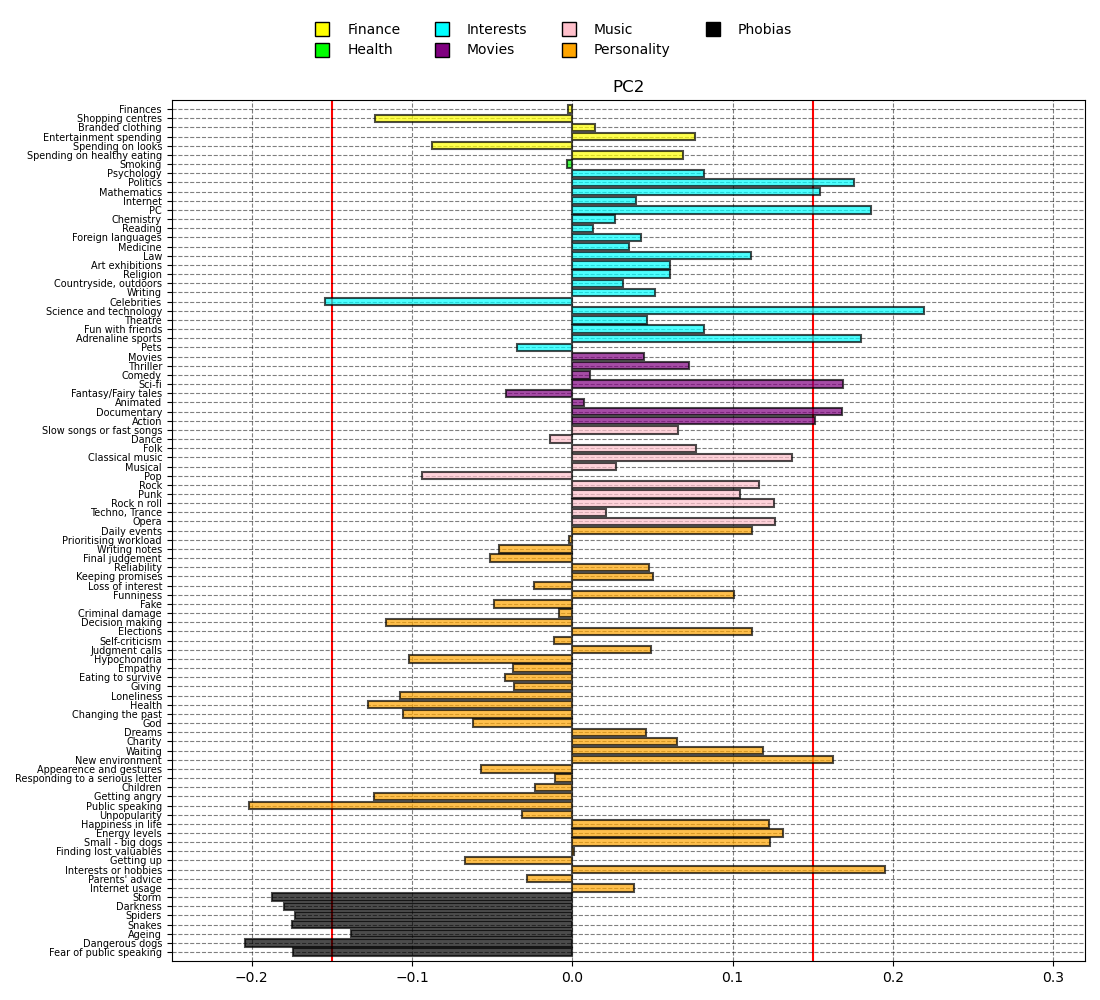

High value positive components: ['Politics' 'Mathematics' 'PC' 'Science and technology'
 'Adrenaline sports' 'Sci-fi' 'Documentary' 'Action' 'New environment'
 'Interests or hobbies']

High value negative components: ['Celebrities' 'Public speaking' 'Storm' 'Darkness' 'Spiders' 'Snakes'
 'Dangerous dogs' 'Fear of public speaking']


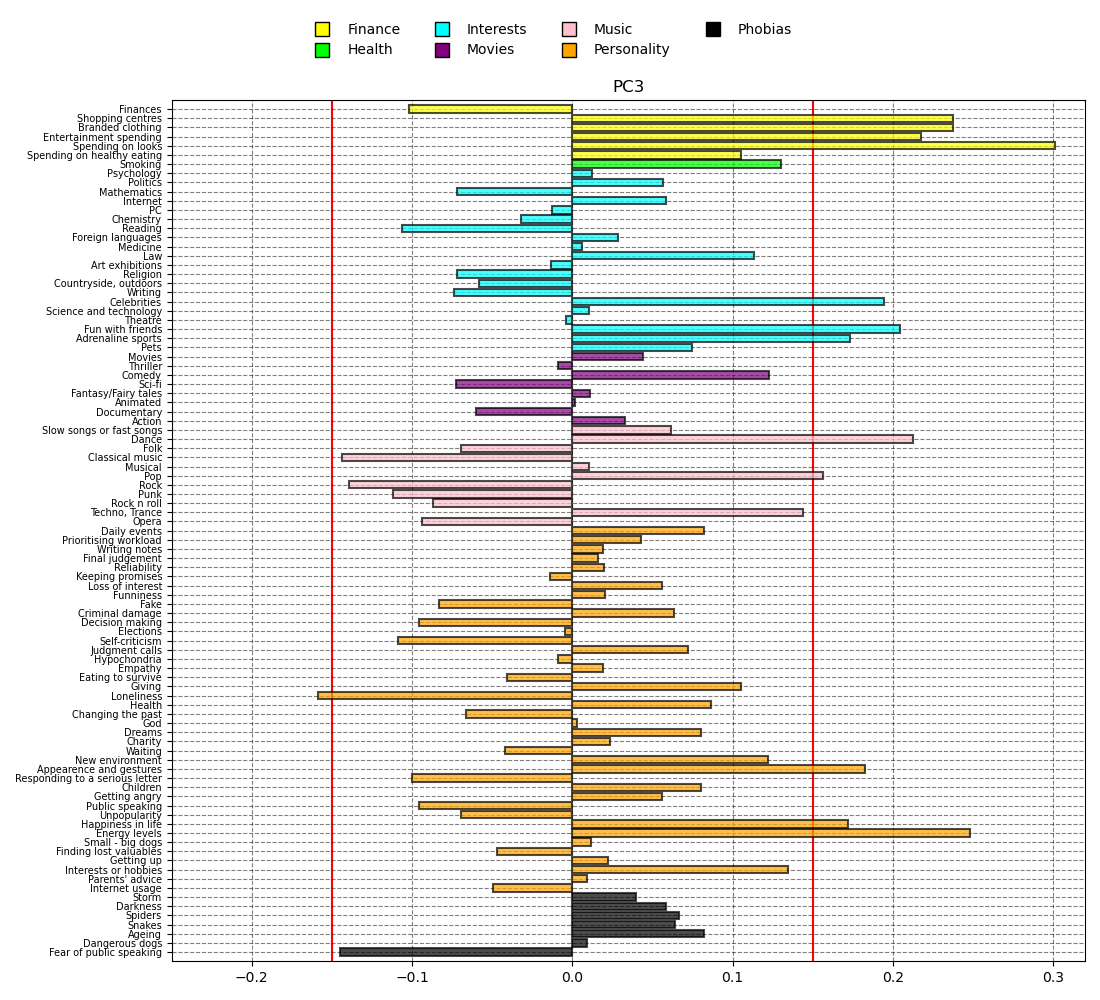

High value positive components: ['Shopping centres' 'Branded clothing' 'Entertainment spending'
 'Spending on looks' 'Celebrities' 'Fun with friends' 'Adrenaline sports'
 'Dance' 'Pop' 'Appearence and gestures' 'Happiness in life'
 'Energy levels']

High value negative components: ['Loneliness']


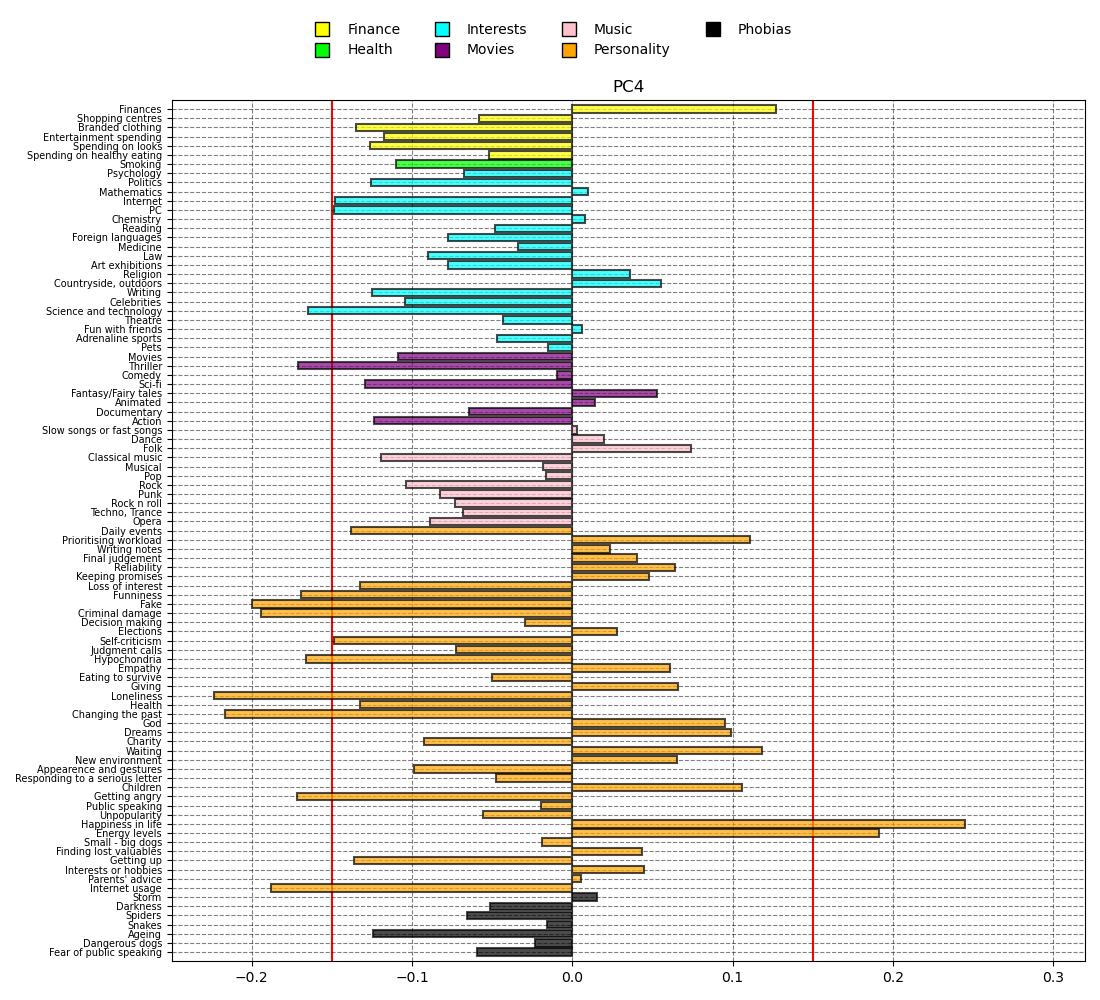

High value positive components: ['Happiness in life' 'Energy levels']

High value negative components: ['Science and technology' 'Thriller' 'Funniness' 'Fake' 'Criminal damage'
 'Hypochondria' 'Loneliness' 'Changing the past' 'Getting angry'
 'Internet usage']


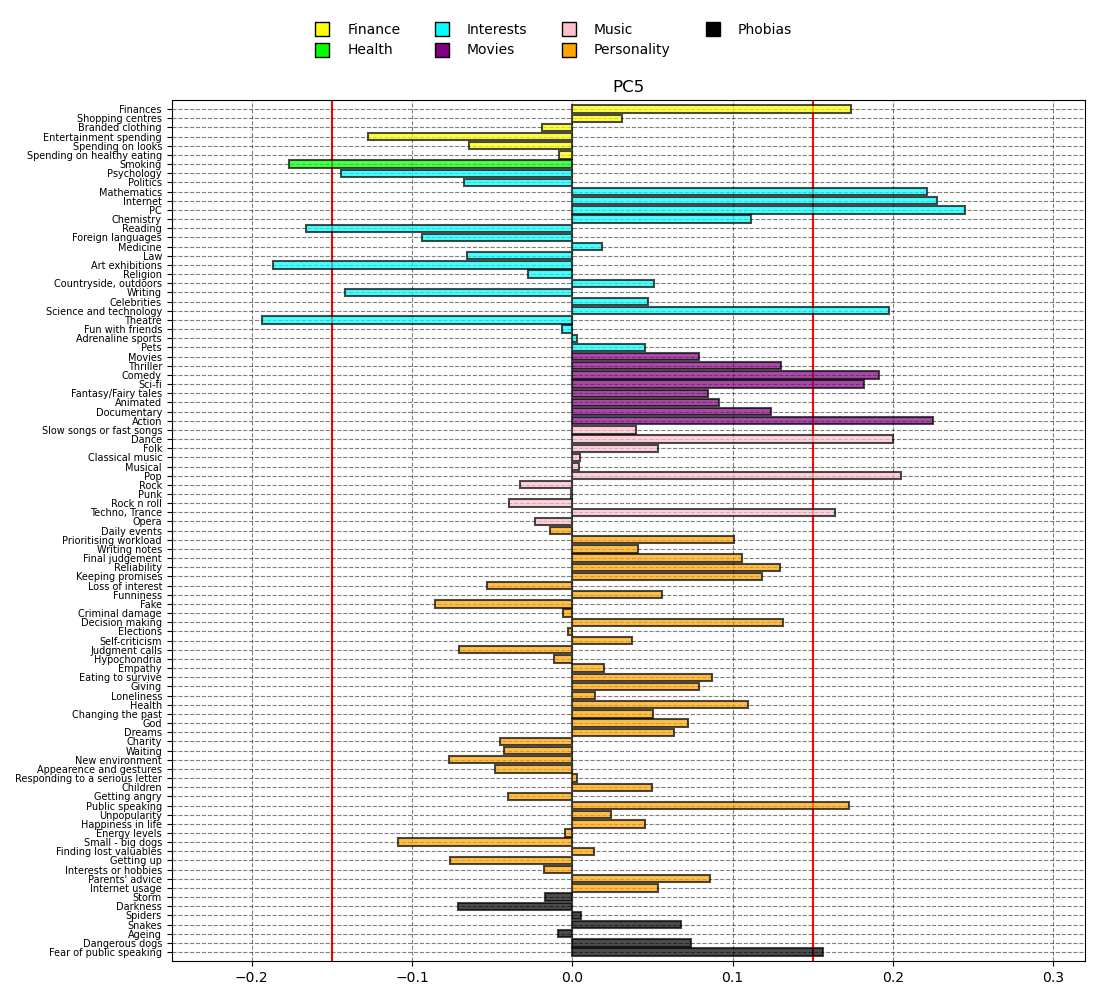

High value positive components: ['Finances' 'Mathematics' 'Internet' 'PC' 'Science and technology'
 'Comedy' 'Sci-fi' 'Action' 'Dance' 'Pop' 'Techno, Trance'
 'Public speaking' 'Fear of public speaking']

High value negative components: ['Smoking' 'Reading' 'Art exhibitions' 'Theatre']


In [14]:
plt.close("all")

PCs = pca_ft.components_

n_responses = len(responses_ft)
n_features = len(feature_names)

feature_indices = range(n_features)

for i in range(m):
    fig_pca = plt.figure(figsize=(11, 10))
    ymin_line = min(feature_indices) - 5
    ymax_line = max(feature_indices) + 5
    plt.ylim(ymin_line, ymax_line)
    plt.vlines(0.15, ymin_line, ymax_line, color="red", zorder=1)
    plt.vlines(-0.15, ymin_line, ymax_line, color="red", zorder=1)
    plt.barh(feature_indices, PCs[i], color=categories_colors, alpha=0.7, height=0.8, edgecolor='black', linewidth=1.5, zorder=2)
    plt.title(f'PC{i+1}')
    plt.grid(True, color="black", linestyle='--', alpha=0.5)
    plt.xlim(-0.25, 0.32)
    plt.ylim(-1, n_features)
    plt.yticks(feature_indices, feature_names, fontsize=7)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.subplots_adjust(top=0.9) 
    fig_pca.legend(handles=categories_legend, loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=4, frameon=False, title_fontsize='large')
    plt.show()
    
    high_value_ind = PCs[i] >= 0.15
    low_value_ind = PCs[i] <= -0.15
    high_features = responses_ft_pp.columns[high_value_ind].values
    low_features = responses_ft_pp.columns[low_value_ind].values
    print(f"High value positive components: {high_features}")
    print(f"\nHigh value negative components: {low_features}")

#### For each PC, write the name you assigned to it and a brief interpretation that motivate the choice (max 100 words per PC):
PC1: <b>Classical Intellectual</b><br>
We see that the principal features in PC1 are all in the field of classical arts, such as opera, art, religion and countryside, all features of a classical intellectual who appreciates this fields.<br><br>
PC2: <b>Rational Adventurer</b><br>
This is suitable because it has high positive values among stem fields, such as PC, science and maths, and in adventures, such as sports, new environment and action. It is also not afraid of the public and not subject to common phobias as snakes, spiders and darkness. Perfect for a stem intelligent person who loves adventure.<br><br>
PC3: <b>Popular Trend Icon</b><br>
This works because it thrives in shopping, spending, appearance, popularity and happiness, suggesting that it uses a lot of energy to keep at the highest of level for fashion.<br><br>
PC4: <b>Happy Natural</b><br>
Thanks to high positive value in happiness and energy and high negative values in science, fake, criminal, getting angry and internet, this name suits perfectly this PC, a down to earth optimist focused on happiness.<br><br>
PC5: <b>Digital Pragmatist</b><br>
This title is a great fit, revolving around high positive value like  math, finance, internet, techno and action, while high negative values such as reading, art, theatre.

#### Write the code for visualizing the score graph (with PC names on the axis):

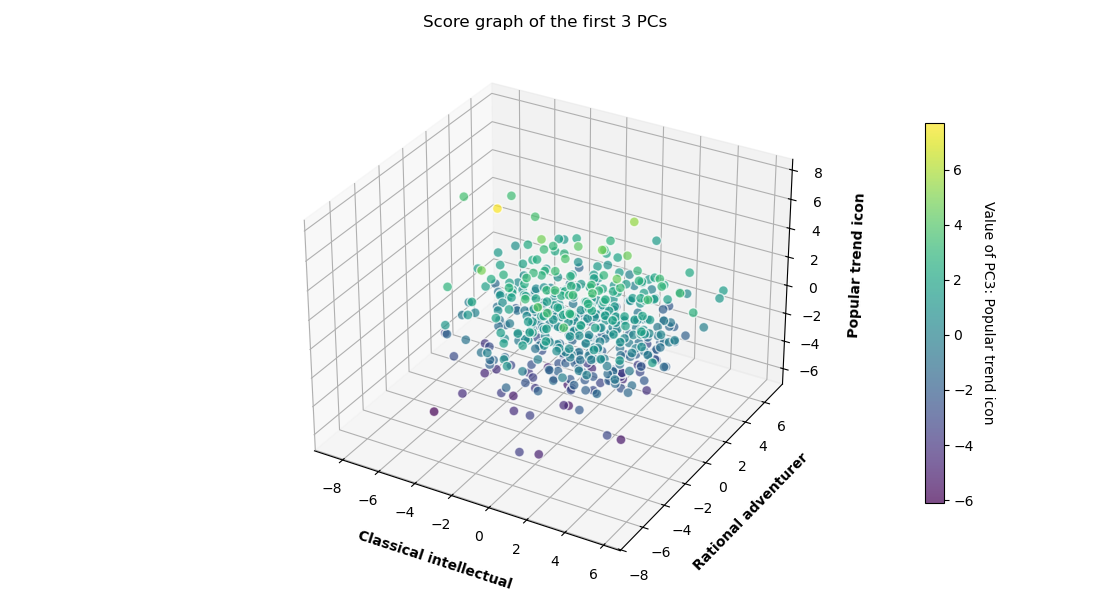

In [18]:
plt.close("all")

transformed_data = pca_ft.transform(responses_ft_pp)
PC_names = ["Classical intellectual", "Rational adventurer", "Popular trend icon", "Happy natural", "Digital pragmatist"]
responses_ft_pca = pd.DataFrame(transformed_data, columns=PC_names)

fig = plt.figure(figsize=(11, 6))
ax = fig.add_subplot(111, projection='3d')
x_col = PC_names[0]
y_col = PC_names[1]
z_col = PC_names[2]
x_data = responses_ft_pca[x_col]
y_data = responses_ft_pca[y_col]
z_data = responses_ft_pca[z_col]
scatter = ax.scatter(x_data, y_data, z_data, c=z_data, cmap='viridis', s=50, alpha=0.7, edgecolor='w')
ax.set_xlabel(x_col, fontsize=10, fontweight='bold', labelpad=10)
ax.set_ylabel(y_col, fontsize=10, fontweight='bold', labelpad=10)
ax.set_zlabel(z_col, fontsize=10, fontweight='bold', labelpad=10)
ax.set_title("Score graph of the first 3 PCs", fontsize=12, pad=10)
cbar = plt.colorbar(scatter, ax=ax, shrink=0.7, pad=0.1)
cbar.set_label(f"Value of PC3: {z_col}", rotation=270, labelpad=15)
plt.tight_layout()
plt.show()

## Exercise 4. $k$-Means

In this exercise, you have to do the following operations:
1. Run the $k$-Means for clustering the data of *responses_ft_pca*, **setting the input argument *random_state* equal to the variable *random_seed*** (i.e., the minimum of the Student IDs).

   In particular, **use the silohuette score for identifying the best value for $k\in\{3, \ldots, 10\}$** and show it by plotting how the score changes w.r.t. $k$.
1. Plot the score graph again, but add the centroids of the cluster and color the points according to their cluster.
1. Visualize the centroids coordinates as barplots and **give a name and an interpretation to them by exploiting the PC names**.


#### Write the code for performing the items of the list above:

n_clusters = 3  -> silhouette score = 0.157
n_clusters = 4  -> silhouette score = 0.152
n_clusters = 5  -> silhouette score = 0.143
n_clusters = 6  -> silhouette score = 0.143
n_clusters = 7  -> silhouette score = 0.139
n_clusters = 8  -> silhouette score = 0.144
n_clusters = 9  -> silhouette score = 0.141
n_clusters = 10 -> silhouette score = 0.146


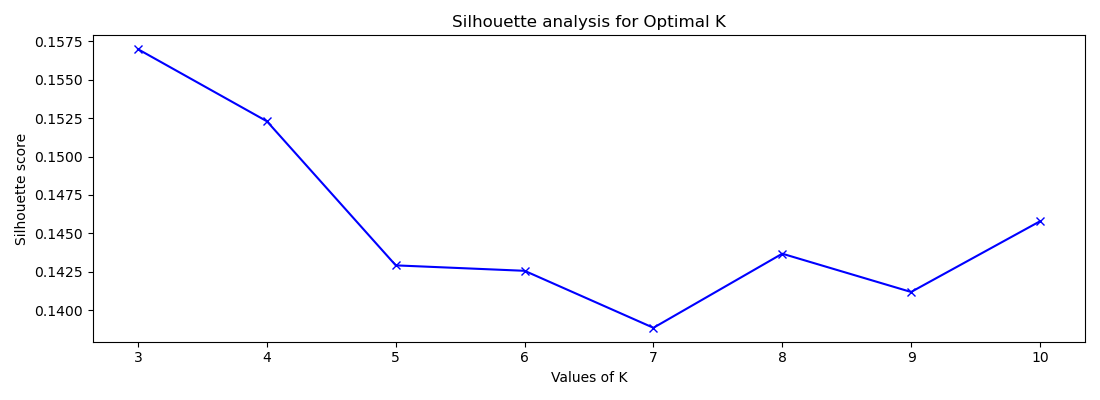

In [21]:
plt.close("all")

k_values = [3, 4, 5, 6, 7, 8, 9, 10]
scores = []
best_score = -np.inf

for k in k_values:
    kmeans_k = KMeans(n_clusters=k, random_state=random_seed)
    labels_k = kmeans_k.fit_predict(responses_ft_pca)
    score_k = silhouette_score(responses_ft_pca, labels_k)
    
    scores.append(score_k)
    print(f"n_clusters = {k:<2} -> silhouette score = {score_k:.3f}")

plt.figure(figsize=(11,4))
plt.plot(k_values, scores, 'bx-')
plt.xlabel('Values of K')
plt.ylabel('Silhouette score')
plt.title('Silhouette analysis for Optimal K')
plt.tight_layout()
plt.show()

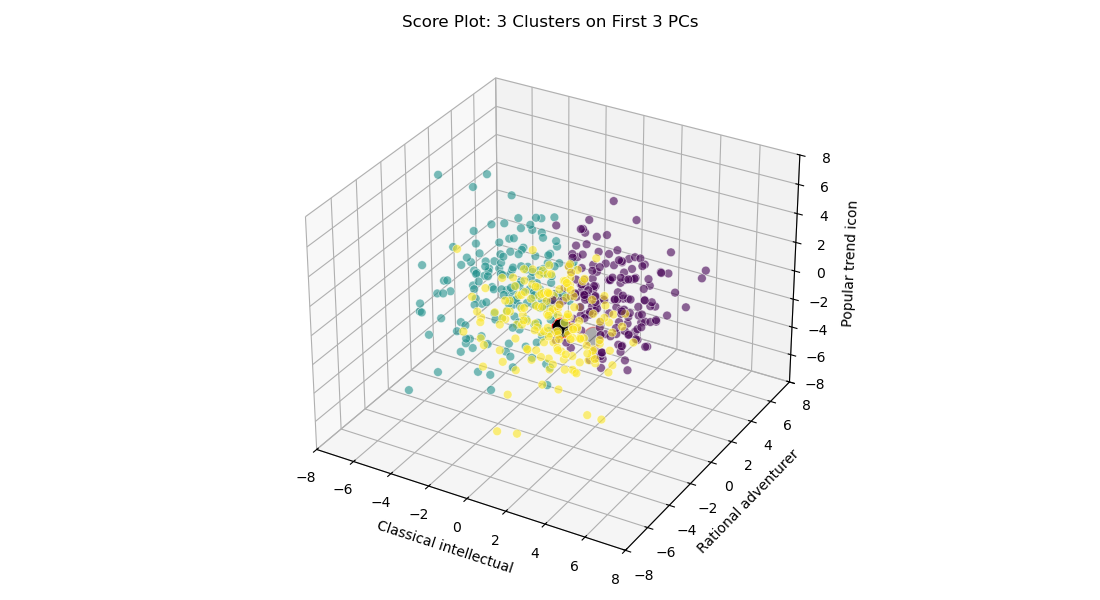

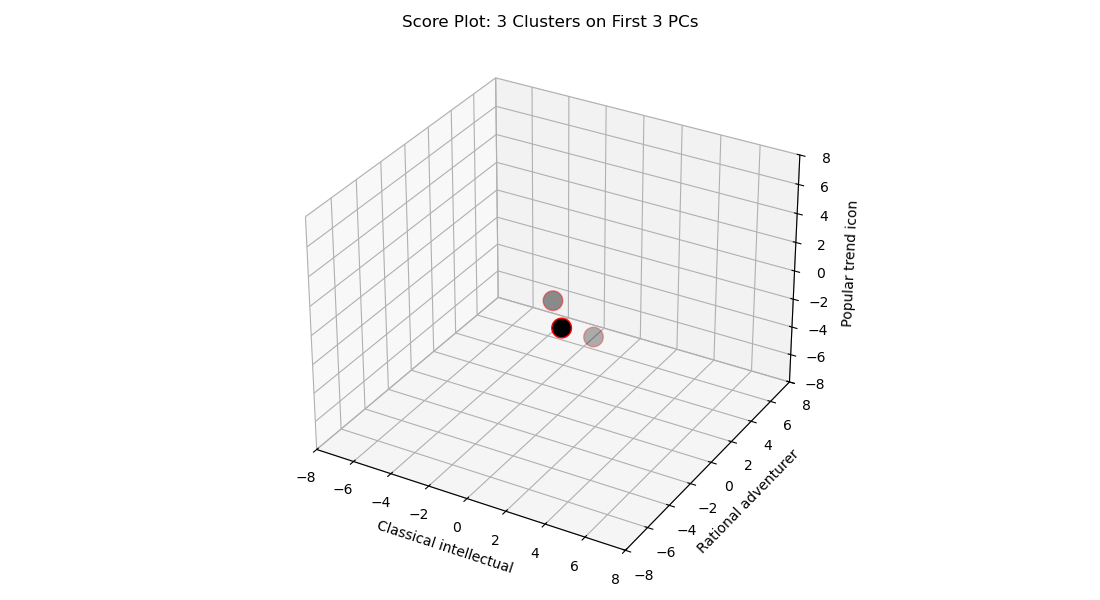

In [23]:
def score_graph(pc_names, pred, num_cluster, centr, pca_features=None):
    fig = plt.figure(figsize=(11, 6))
    ax = fig.add_subplot(111, projection='3d')
    if pca_features is not None:
        ax.scatter(pca_features[pc_names[0]], pca_features[pc_names[1]], pca_features[pc_names[2]], c=pred, cmap='viridis', s=40, alpha=0.6, edgecolors='w', linewidth=0.5)
    ax.scatter(centr[0, :3], centr[1, :3], centr[2, :3], c='black', s=200, edgecolors='red')
    ax.set_xlim(-8, 8)
    ax.set_ylim(-8, 8)
    ax.set_zlim(-8, 8)
    ax.set_xlabel(pc_names[0])
    ax.set_ylabel(pc_names[1])
    ax.set_zlabel(pc_names[2])
    ax.set_title(f'Score Plot: {num_cluster} Clusters on First 3 PCs')
    plt.tight_layout()
    plt.show()

plt.close("all")

best_k = k_values[np.argmax(scores)]

kmeans = KMeans(n_clusters=best_k, random_state=random_seed)
predictions = kmeans.fit_predict(responses_ft_pca)
centroids = kmeans.cluster_centers_

score_graph(PC_names, predictions, best_k, centroids, responses_ft_pca)
score_graph(PC_names, predictions, best_k, centroids)

            Classical intellectual  Rational adventurer  Popular trend icon  \
Centroid 1                1.846038             1.683063           -0.033824   
Centroid 2               -2.825871             0.356171           -0.344750   
Centroid 3                0.875505            -1.981790            0.359857   

            Happy natural  Digital pragmatist  
Centroid 1      -0.384380           -0.191944  
Centroid 2      -0.089617            0.116608  
Centroid 3       0.460448            0.076964  


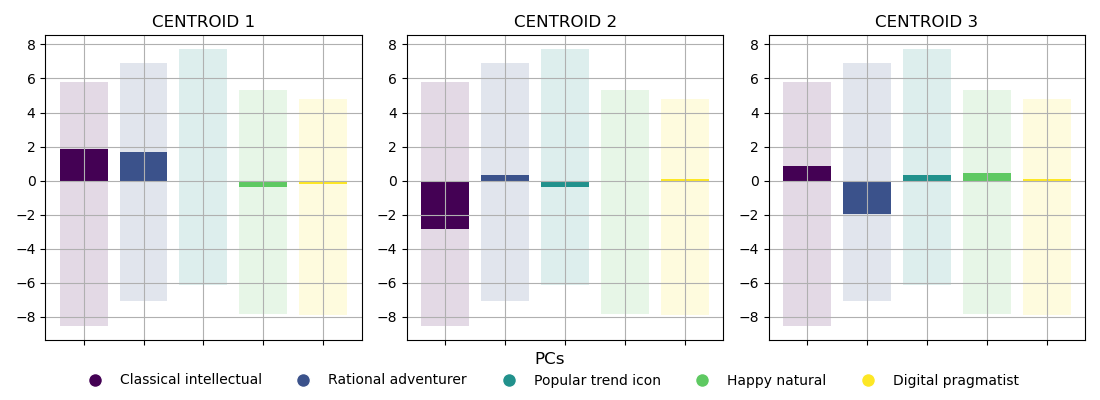

In [26]:
plt.close("all")

print(pd.DataFrame(centroids, columns=PC_names, index=[f"Centroid {k+1}" for k in range(best_k)]))

maxs_features_pca = responses_ft_pca.max(axis=0)
mins_features_pca = responses_ft_pca.min(axis=0)

indices_colors_centroids = np.linspace(0, 1, m)
colors_centroids = [plt.cm.viridis(i) for i in indices_colors_centroids]
legend_centroids = []

for i in range(m):
    legend_centroids.append(Line2D([0], [0], marker='o', color='w', label=PC_names[i], markerfacecolor=colors_centroids[i], markersize=10))

fig, ax = plt.subplots(1, best_k, figsize=(11, 4))
for i in range(0, best_k):
    ax[i].bar(np.arange(centroids.shape[1]), maxs_features_pca, color=colors_centroids, alpha=0.15)
    ax[i].bar(np.arange(centroids.shape[1]), mins_features_pca, color=colors_centroids, alpha=0.15)
    ax[i].bar(np.arange(centroids.shape[1]), centroids[i, :], color=colors_centroids)
    ax[i].grid(visible=True, which='both')
    ax[i].set_title(f'CENTROID {i+1}')
    ax[i].set_xticklabels(labels=[])

fig.legend(handles=legend_centroids, loc='lower center', bbox_to_anchor=(0.5, 0), ncol=5, frameon=False, title='PCs', title_fontsize='large')
plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
plt.show()

#### For each Centroid, write the name you assigned to it and a brief interpretation that motivate the choice by exploiting the PC names(max 100 words per centroid):
Centroid 1: "The Classical Adventurer"<br>
High PC1 1.84 and High PC2 1.68.<br>
This group is unique because they score highly in both Classical Intellectual and Rational Adventurer. They are well-rounded, academic, and adventurous.<br><br>

Centroid 2: "The Anti-Academic"<br>
Extremely Low PC1 -2.82.<br>
This value is massively negative. Since PC1 represents Classical Intellectual, this group strongly dislikes those traditional culture topics.<br>
They define themselves by rejecting the classical intellectual lifestyle, preferring more modern or practical entertainments over traditional hobbies.<br><br>

Centroid 3: "The Cautious Humanist"<br>
Very Low PC2 -1.98 and Moderate PC1 0.88.<br>
A negative score in PC2 suggests this group might have more phobias and, in general, might be more afraid than normal, also dislikes STEM and Action.<br>
But the high score in PC1 suggests that they still enjoy the arts, reading and the more classical culture.<br><br>

## Exercise 5. Cluster External Evaluations

In this exercise, you have to do the following operations:
1. Select a subset meaningful labels for performing an external evaluation of the clustering results.
1. For each selected label, visualize the distribution of the label in each cluster and in the whole dataset.
1. Visualize the score graph with dots colored with respect to the label value; then, visualize the clusters in separated score-graphs, coloring the points according to the label values.


#### List the Labels you consider meaningful for an external cluster evaluation and motivate your choice (max 50 words per label):
For the external evaluation we will be considering 4 labels:
1. Gender<br>
We chose gender to see if in this dataset there is some correlation between male-adventurers, female-cautious humanist and all the other possibilities.
2. Education<br>
Analysing education allows us to see whether the most educated people are the one more interested in classical arts/STEM rather than in adventure for example.
3. Only child<br>
It is interesting to see if effectively exists a correlation between different archetypes and having siblings, does being an only child lead you to a certain personality?
4. Age<br>
Does age define what people are most interested in? For example, will younger people be more adventurous/anti-academic?
5. Hometown type<br>
We selected the hometown type to see if different growing conditions affect someone's personality, for example if city means more interested in tech and if village means leaning toward nature.


#### Write the code for the visualizations cited in item 2 above:

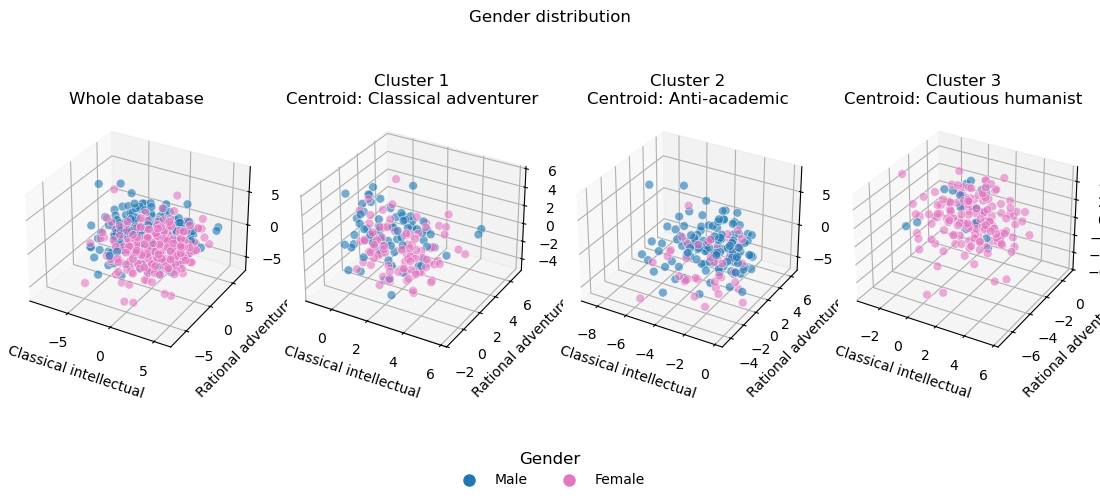

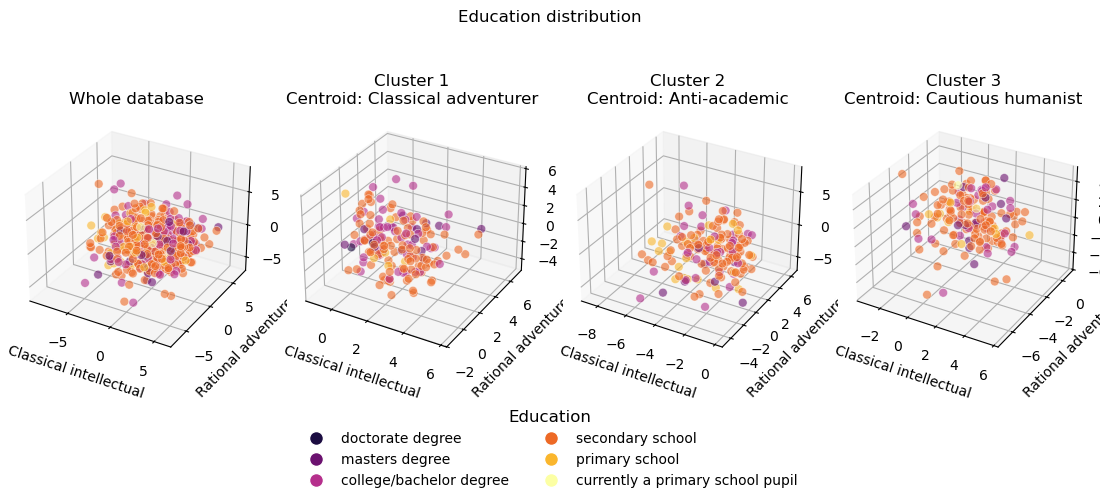

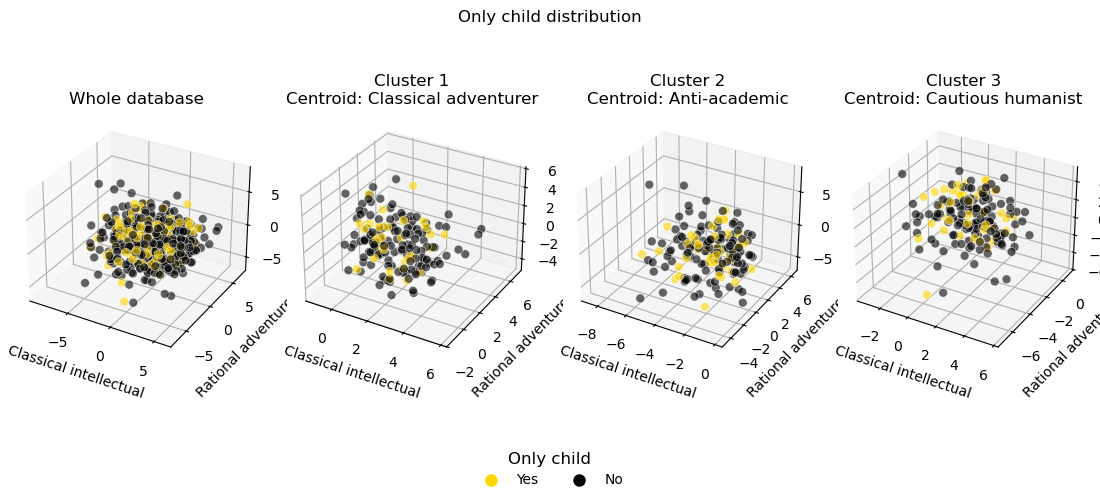

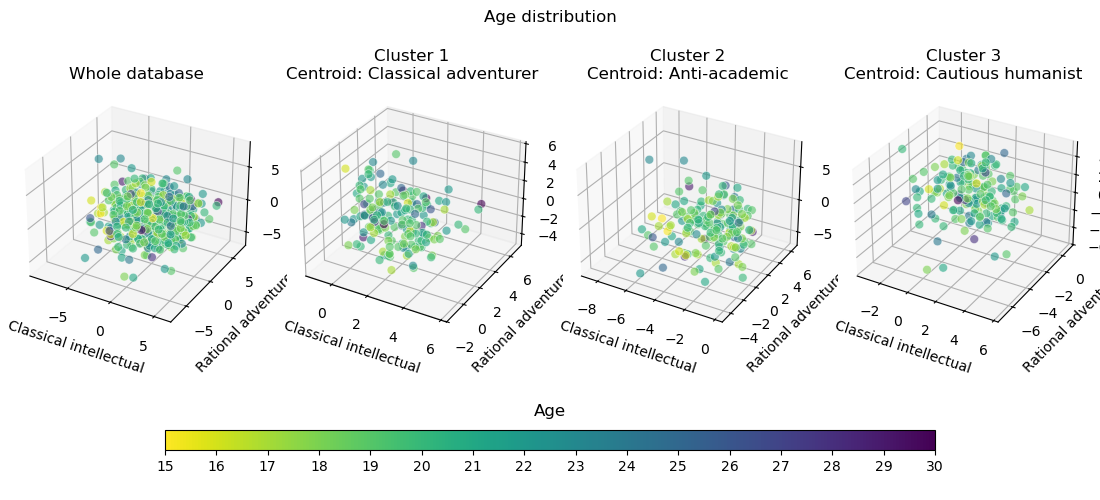

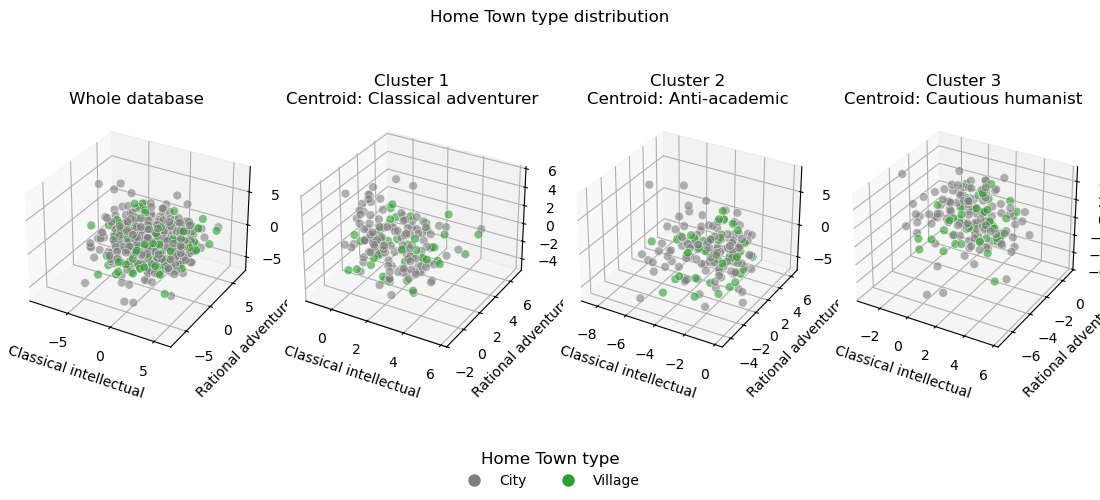

In [ ]:
plt.close("all")

centroids_names = ["Classical adventurer", "Anti-academic", "Cautious humanist"]

PC_important_names = ["Classical intellectual", "Rational adventurer", "Popular trend icon"]
PC_important_index = [0, 1, 3]
important_labels = ["Gender", "Education", "Only child", "Age", "Home Town type"]

color_gender = responses_lb['Gender'].map({'male': '#1f77b4', 'female': '#e377c2'})
colors_inferno = ['#fcffa4', '#fab62d', '#ed6925', '#b52f8c', '#6b116f', '#1b0c41']
education_map = { 'currently a primary school pupil': '#fcffa4', 'primary school': '#fab62d', 'secondary school': '#ed6925', 'college/bachelor degree': '#b52f8c', 'masters degree': '#6b116f', 'doctorate degree': '#1b0c41'}
color_education = responses_lb['Education'].map(education_map)
color_only_child = responses_lb['Only child'].map({'yes': '#FFD700', 'no': '#000000'})
norm_age = plt.Normalize(responses_lb['Age'].min(), responses_lb['Age'].max())
cmap_age = plt.get_cmap('viridis_r')
colors_age = cmap_age(norm_age(responses_lb['Age']))
color_home_town = responses_lb['Home Town Type'].map({'city': '#7f7f7f', 'village': '#2ca02c'})
all_colors = [color_gender, color_education, color_only_child, colors_age, color_home_town]

gender_legend = [Line2D([0], [0], marker='o', color='w', label='Male', markerfacecolor='#1f77b4', markersize=10), 
                 Line2D([0], [0], marker='o', color='w', label='Female', markerfacecolor='#e377c2', markersize=10)]
education_legend = [Line2D([0], [0], marker='o', color='w', label='doctorate degree', markerfacecolor="#1b0c41", markersize=10),
                    Line2D([0], [0], marker='o', color='w', label='masters degree', markerfacecolor='#6b116f', markersize=10),
                    Line2D([0], [0], marker='o', color='w', label='college/bachelor degree', markerfacecolor='#b52f8c', markersize=10),
                    Line2D([0], [0], marker='o', color='w', label='secondary school', markerfacecolor='#ed6925', markersize=10),
                    Line2D([0], [0], marker='o', color='w', label='primary school', markerfacecolor='#fab62d', markersize=10),
                    Line2D([0], [0], marker='o', color='w', label='currently a primary school pupil', markerfacecolor='#fcffa4', markersize=10)]
only_child_legend = [Line2D([0], [0], marker='o', color='w', label='Yes', markerfacecolor='#FFD700', markersize=10), 
                     Line2D([0], [0], marker='o', color='w', label='No', markerfacecolor='#000000', markersize=10)]
home_town_legend = [Line2D([0], [0], marker='o', color='w', label='City', markerfacecolor='#7f7f7f', markersize=10), 
                    Line2D([0], [0], marker='o', color='w', label='Village', markerfacecolor='#2ca02c', markersize=10)]
all_legends = [gender_legend, education_legend, only_child_legend, "", home_town_legend]

for i in range(len(important_labels)):
    fig = plt.figure(figsize=(11, 5)) 
    fig.suptitle(f'{important_labels[i]} distribution')
    ax = fig.add_subplot(1, 4, 1, projection='3d')
    scatter = ax.scatter(responses_ft_pca[PC_important_names[0]], responses_ft_pca[PC_important_names[1]], responses_ft_pca[PC_important_names[2]], c=all_colors[i], s=40, alpha=0.6, edgecolors='w', linewidth=0.5)
    ax.set_xlabel(PC_important_names[0])
    ax.set_ylabel(PC_important_names[1])
    ax.set_zlabel(PC_important_names[2])
    ax.set_title(f'Whole database')
    
    for j in range(best_k):
        mask = predictions == j
        temp_ft = responses_ft_pca[mask]
        
        ax = fig.add_subplot(1, 4, j+2, projection='3d')
        scatter = ax.scatter(
            temp_ft[PC_important_names[0]], 
            temp_ft[PC_important_names[1]], 
            temp_ft[PC_important_names[2]], 
            c=all_colors[i][mask], 
            s=40, 
            alpha=0.6, 
            edgecolors='w', 
            linewidth=0.5
        )
    
        ax.set_xlabel(PC_important_names[0])
        ax.set_ylabel(PC_important_names[1])
        ax.set_zlabel(PC_important_names[2])
        ax.set_title(f"Cluster {j+1}\nCentroid: {centroids_names[j]}")
    
    if i == 3:
        norm_age = plt.Normalize(vmin=15, vmax=30)
        sm = plt.cm.ScalarMappable(cmap=cmap_age, norm=norm_age)
        sm.set_array([])
        plt.subplots_adjust(left=0.01, right=0.99, top=0.90, bottom=0.25, wspace=0.1)
        cbar_ax = fig.add_axes([0.15, 0.10, 0.7, 0.04]) 
        cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', ticks=range(15, 31))
        cbar_ax.set_title(f'{important_labels[i]}', fontsize=12, pad=10)
    else:
        fig.legend(handles=all_legends[i], loc='lower center', bbox_to_anchor=(0.5, 0), ncol=2, frameon=False, title=important_labels[i], title_fontsize='large')
        plt.subplots_adjust(left=0.01, right=0.99, top=0.90, bottom=0.15, wspace=0.1)

    plt.show()

#### For each selected label, comment the results observed in the visualizations (max 100 words per label):
1. Gender<br>
The 'Gender' label is the only one that is able to tell us something about the dataset, we see that:<br>
<ul>
    <li>Whole dataset: the males tend to be more 'Rational adventurer' and less 'Classical intellectual', the females instead are the opposite, they lean towards the 'Classical intellectual' rather than 'Rational adventurer'.<br>
    <li>Cluster 1. 'Classical adventurer': in this cluster we see that the distribution between males and females is more or less the same, nothing stands out.<br>
    <li>Cluster 2. 'Anti-academic': this cluster is charachterized by almost exclusively males, this is because males tend to be worse student, therefore making them 'Anti-academic'.<br>
    <li>Cluster 3. 'Cautious humanist': here instead we can see a female dominated cluster, since most of them move away from 'Rational adventurer' and lean towards 'Classical intellectual'. This suggests that they are more inclined to fear and studies, hence the 'Cautous humanist'.
</ul>
<br>
We can observe from the graphs instead that for all the other labels the score graphs doesn't tell us anything, the distribution seems equals and the labels does not lean towards an archetype or another, we can conclude that from the features selected only 'Gender' is able to tell us something. 


## Exercise 6. Cluster Internal Evaluations

In this exercise, you have to do the following operations:
1. For each cluster, measure the corresponding average silhouette score
1. Visualize the silhouette of the clusters and the general one of the clustering and compare them


#### Write the code for computing the silhouette scores and for visualizing them:

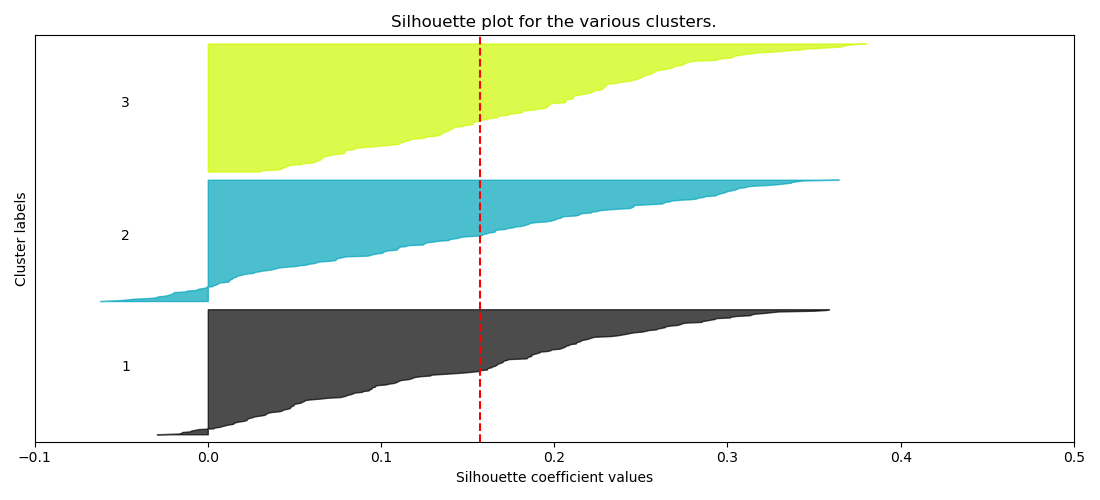

In [37]:
plt.close("all")

sil_avg = silhouette_score(responses_ft_pca, predictions)
sample_sil_values = silhouette_samples(responses_ft_pca, predictions)

fig, ax1 = plt.subplots(1, 1)
fig.set_size_inches(11, 5)
ax1.set_xlim([-0.1, 0.5])
ax1.set_ylim([0, len(responses_ft_pca) + (best_k + 1) * 10])
y_lower = 10
for i in range(best_k):
    ith_cluster_silhouette_values = sample_sil_values[predictions == i]
    ith_cluster_silhouette_values.sort()
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i
    color = cm.nipy_spectral(float(i) / best_k)
    ax1.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values, facecolor=color, edgecolor=color, alpha=0.7)
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i+1))
    y_lower = y_upper + 10 

ax1.set_title("Silhouette plot for the various clusters.")
ax1.set_xlabel("Silhouette coefficient values")
ax1.set_ylabel("Cluster labels")
ax1.axvline(x=sil_avg, color="red", linestyle="--")
ax1.set_yticks([])
ax1.set_xticks([-0.1, 0, 0.1, 0.2, 0.3, 0.4, 0.5])
plt.tight_layout()
plt.show()

Silhouette scores
Whole dataset: 0.1570
Cluster 1:     0.1445
Cluster 2:     0.1383
Cluster 3:     0.1868


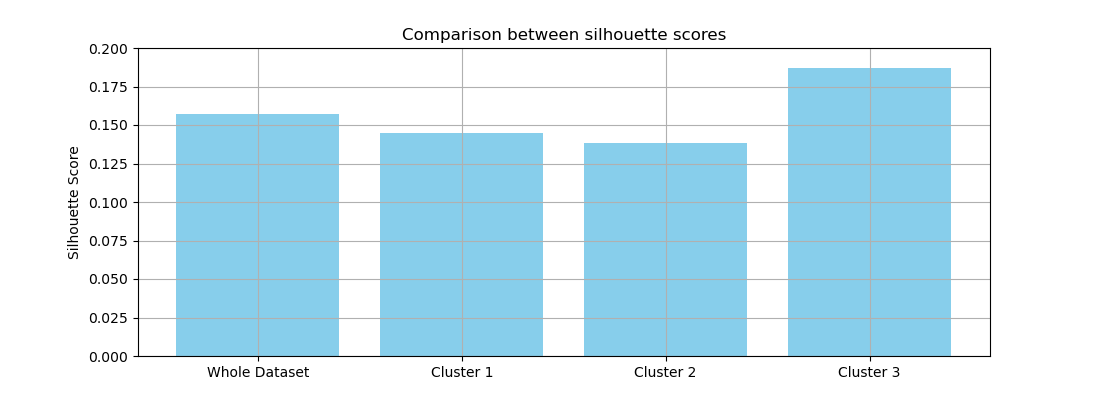

In [40]:
plt.close("all")

print(f'Silhouette scores')
print(f'Whole dataset: {sil_avg:.4f}')
print(f'{'Cluster 1: ':<15}{np.mean(sample_sil_values[predictions == 0]):.4f}')
print(f'{'Cluster 2: ':<15}{np.mean(sample_sil_values[predictions == 1]):.4f}')
print(f'{'Cluster 3: ':<15}{np.mean(sample_sil_values[predictions == 2]):.4f}')

sil_values = [sil_avg]
name_bars = ['Whole Dataset']

for i in range(best_k):
    sil_values.append(np.mean(sample_sil_values[predictions == i]))
    name_bars.append(f'Cluster {i+1}')
    
plt.figure(figsize=(11, 4))
plt.grid(visible=True)
plt.bar(name_bars, sil_values, color='skyblue')
plt.title('Comparison between silhouette scores')
plt.ylabel('Silhouette Score')
plt.ylim(0, 0.2)
plt.show()

#### Comment the results, also considering the results observed previously (e.g., score graphs, centroids, etc. - max 150 words):
The graph shows that the third cluster is the best one, almost reaching a silhouette score of 0.2, surpassing the average silhouette score of the whole dataset.<br>
The first two clusters instead perform quite similar, lowering the average silhouette score.<br>
In conclusion the cluster built around the centroid 'Cautious humanist' is the most cohesive.